# Recovering Nanda et al.'s grokking results

This notebook checks that our one-layer model trained on hop-1 modular addition (`runs/anchor_p113_h1`: p = 113, 30% of pairs, learned positions, weight decay 1) learned the algorithm described in *Progress measures for grokking via mechanistic interpretability*:

1. **Training dynamics:** memorization, then circuit formation, then cleanup. Test loss falls long after train loss.
2. **Sparse embedding:** W_E uses only a handful of key frequencies w.
3. **Periodic attention:** from `=`, the heads' attention to `a` and `b` varies periodically with the operands.
4. **Neurons cluster by frequency:** each MLP neuron at `=` is almost entirely a function of one key frequency, built from cos/sin(wa), cos/sin(wb) and their products.
5. **Neuron-logit map:** W_L = W_U^T W_out reads each neuron cluster out at its own frequency.
6. **Logits form a clock:** logit(c) ≈ Σ_w α_w cos(w(a + b − c)). Restricted and excluded loss test this.
7. **Trig-identity replacement:** replacing every neuron with only its key-frequency terms keeps the model working, and removing those terms breaks it.
8. **Progress measures over training,** recomputed from the saved checkpoints.

Everything is computed at `=` on the full p × p table of hop-1 prompts.

In [1]:
# setup: run from the repo root so paths resolve, and import the code in src/
import os
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import torch as t
import matplotlib.pyplot as plt

import analysis
import mech
import plot_progress as pp
import progress

%matplotlib inline
t.set_grad_enabled(False)
print("torch", t.__version__, "| cuda:", t.cuda.is_available())

torch 2.14.1+cu130 | cuda: True


In [2]:
MUTED = "#c8c7c2"


def panel(ax, title, xlabel, ylabel, log_y=False):
    """style one axis the same way as the run figures.

    args:
        ax: matplotlib axis.
        title: panel title.
        xlabel: x-axis label.
        ylabel: y-axis label.
        log_y: use a log y scale.
    """
    pp.style_axis(ax, title, ylabel, log_y=log_y)
    ax.set_xlabel(xlabel, fontsize=9, color=pp.INK_2)


def freq_bars(ax, norms, highlight, title, ylabel="norm"):
    """bar chart of per-frequency norms, highlighting chosen frequencies and labelling the largest.

    args:
        ax: matplotlib axis.
        norms: tensor of shape (p//2 + 1,) from mech.freq_norms (index 0 is the constant).
        highlight: frequencies drawn in the accent colour.
        title: panel title.
        ylabel: y-axis label.
    """
    f = np.arange(1, len(norms))
    v = norms[1:].cpu().numpy()
    ax.bar(f, v, color=[pp.SERIES[0] if x in highlight else MUTED for x in f], width=0.8)
    for x in np.argsort(-v)[:5]:
        ax.annotate(str(f[x]), (f[x], v[x]), xytext=(0, 2), textcoords="offset points",
                    ha="center", fontsize=7, color=pp.INK_2)
    panel(ax, title, "frequency", ylabel)


def new_fig(n_rows, n_cols, width=12.5, height=3.8):
    """make a figure on the shared surface colour.

    args:
        n_rows: rows of panels.
        n_cols: columns of panels.
        width: figure width in inches.
        height: height per row in inches.
    returns:
        (figure, flat list of axes).
    """
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(width, height * n_rows), facecolor=pp.SURFACE, squeeze=False)
    return fig, list(axes.flat)

## Parameters

In [3]:
RUN_DIR = "runs/anchor_p113_h1"
CHECKPOINT = "final.pt"
DEVICE = "cpu" 

In [4]:
run = analysis.load_run(RUN_DIR, device=DEVICE)
model = analysis.load_model(run, run["run_dir"] / "checkpoints" / CHECKPOINT, DEVICE)
(run["run_dir"] / "analysis").mkdir(exist_ok=True)
p = run["cfg"].p
tokens, labels, is_train = run["data"]["grid"]
# the grid is stored in pair-index order: row a * p + b holds the prompt "a b ="
a_idx, b_idx = t.meshgrid(t.arange(p), t.arange(p), indexing="ij")
assert t.equal(tokens[:, 0], a_idx.flatten()) and t.equal(tokens[:, 1], b_idx.flatten())

logits, cache = mech.run_cache(model, tokens)
basis = progress.fourier_basis(p)
measures = progress.progress_measures(model, tokens, labels, is_train, 1)
KEYS = measures["key_freqs"]
print(run["cfg"])
print(f"train pairs: {int(is_train.sum())} of {p * p}")
for name, mask in [("train", is_train), ("test", ~is_train)]:
    loss, acc = mech.loss_and_acc(logits[mask], labels[mask])
    print(f"{name:<5} loss {loss:.2e}  acc {acc:.4f}")
print("key frequencies (largest clock component of the logits first):", KEYS)
print("logit norm per key frequency:", [round(measures["logit_freq_norms"][f - 1], 1) for f in KEYS])

ModelConfig(p=113, pos='learned', n_ctx=3, norm='none', n_prelude=0, k=1, core_shared=True, n_core_copies=1, injection='none', state_init='embed', n_coda=0, state_norm=False, d_model=128, num_heads=4, d_head=32, d_mlp=512)
train pairs: 3830 of 12769
train loss 9.81e-08  acc 1.0000
test  loss 2.44e-07  acc 1.0000
key frequencies (largest clock component of the logits first): [37, 1, 49, 33, 15]
logit norm per key frequency: [12374.4, 12138.8, 10996.9, 7269.7, 736.7]


## 1. Training dynamics

Logged during training (every 100 steps). The dashed lines are boundaries taken from the curves themselves:
- **End of memorization:** the test loss peak.
- **Grokking:** the step where test accuracy on the grid first passes 0.5.
- **End of cleanup:** the step where Σw² first comes within 1% of its final value.

Nanda et al. report about 1.4k, 9.4k and 13k steps for their run.

end of memorization 1400, grokking 10300, end of cleanup 16900


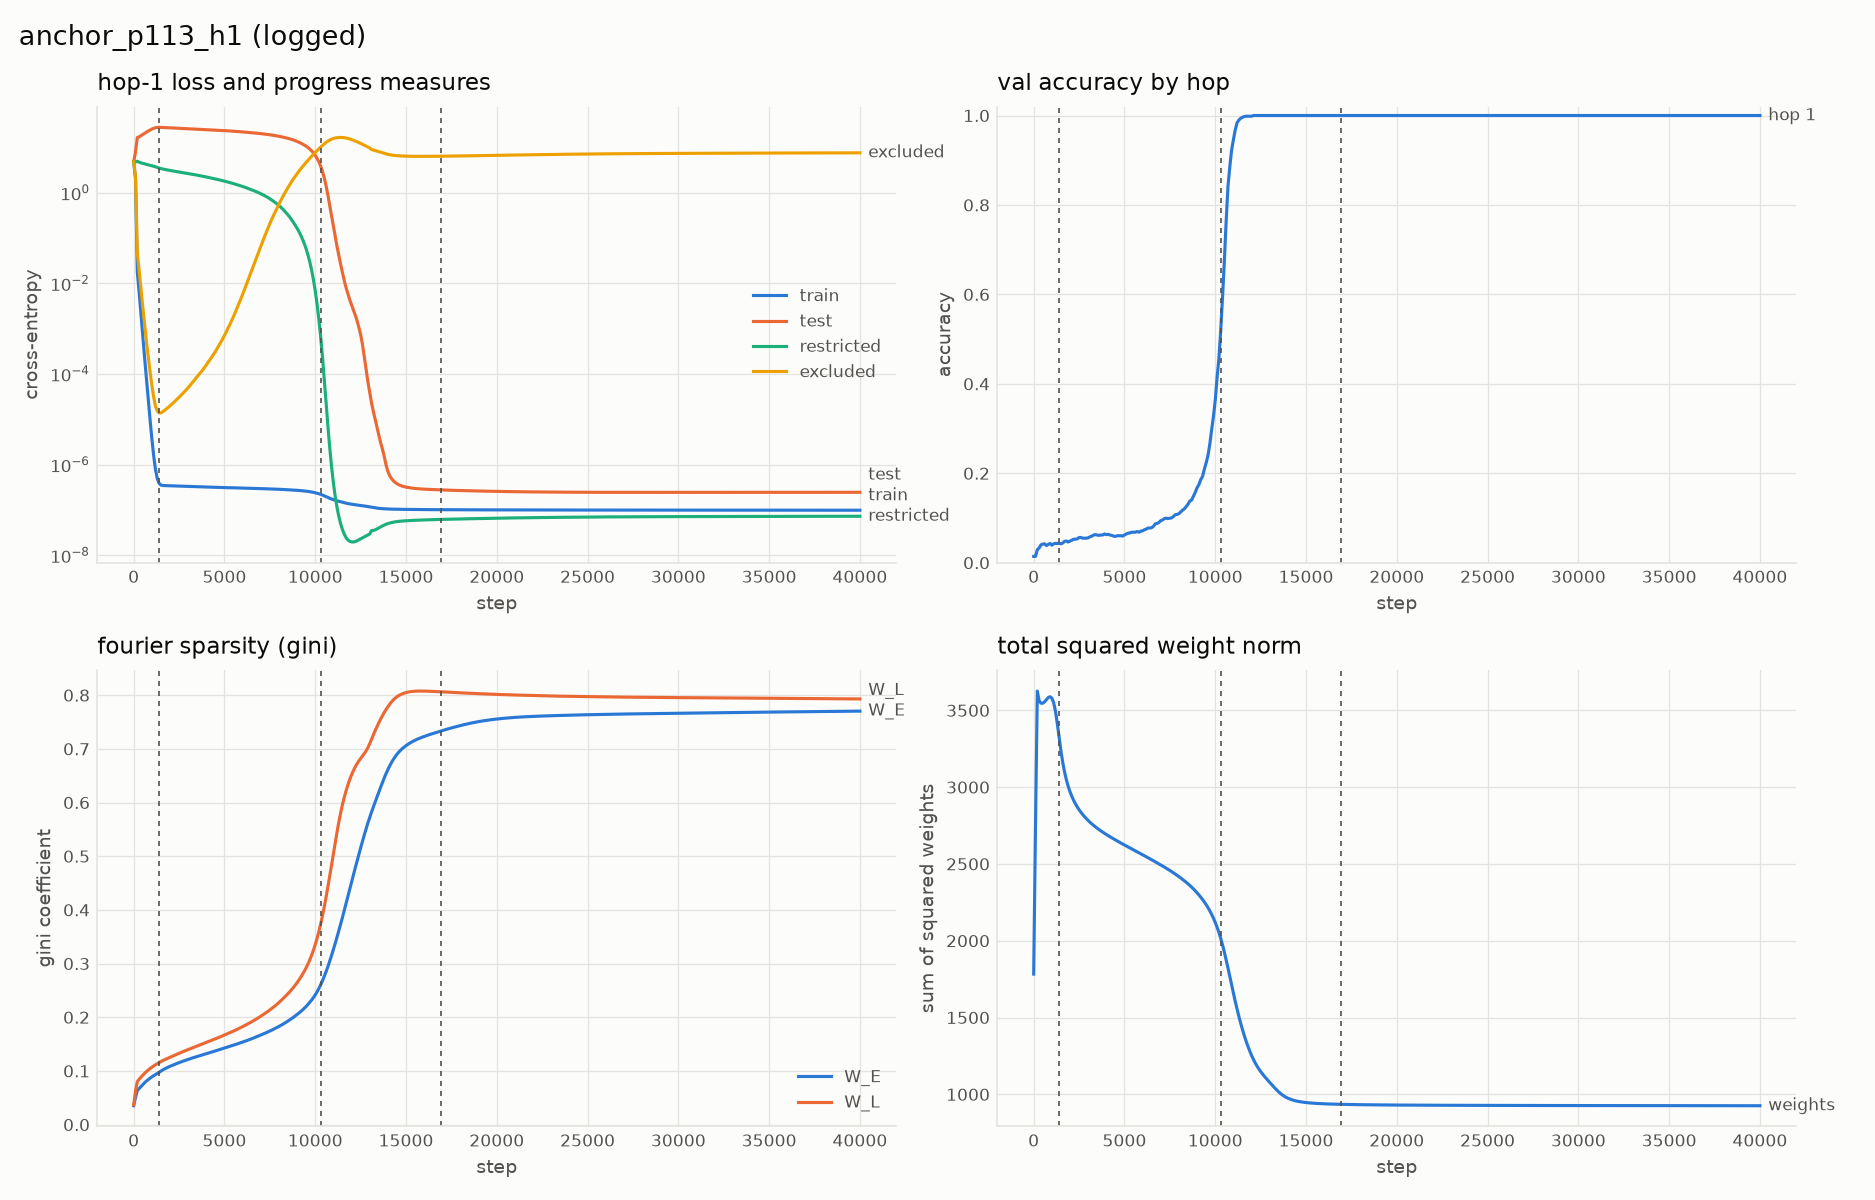

In [5]:
logged = pp.load_evals(run["run_dir"])
steps = [r["step"] for r in logged]
test_loss = [r["progress"]["grid_test_loss"] for r in logged]
test_acc = [r["progress"]["grid_test_acc"] for r in logged]
w = [r["progress"]["sum_sq_weights"] for r in logged]
mem_end = steps[int(np.argmax(test_loss))]
grok = next(s for s, a in zip(steps, test_acc) if a > 0.5)
clean_end = next(s for s, x in zip(steps, w) if s > grok and abs(x - w[-1]) < 0.01 * w[-1])
PHASES = [mem_end, grok, clean_end]
print(f"end of memorization {mem_end}, grokking {grok}, end of cleanup {clean_end}")
out = pp.plot_rows(logged, f"{run['name']} (logged)", run["run_dir"] / "analysis" / "nanda_progress.png", PHASES)
from IPython.display import Image, display
display(Image(filename=str(out)))

## 2. The embedding is sparse in the Fourier basis

The norm of W_E's component at each frequency (cos and sin combined). Key frequencies are highlighted. The first checkpoint (step 100) is shown for comparison: training concentrates the embedding onto a few frequencies.

step 100: share of W_E norm^2 in the top 5 frequencies = 0.112, gini = 0.039
final (final.pt): share of W_E norm^2 in the top 5 frequencies = 0.994, gini = 0.769


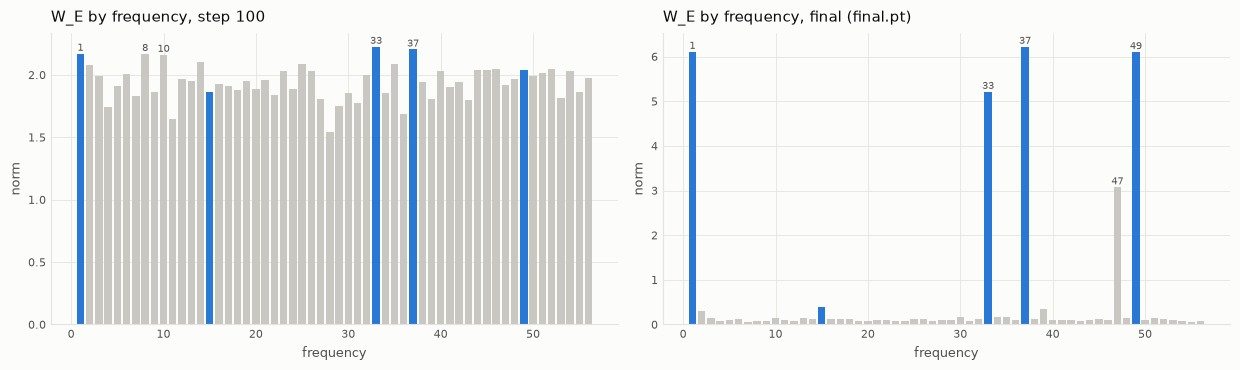

In [6]:
first_step, first_path = analysis.checkpoints(run)[0]
early = analysis.load_model(run, first_path, DEVICE)
fig, axes = new_fig(1, 2)
for ax, (label, m) in zip(axes, [(f"step {first_step}", early), (f"final ({CHECKPOINT})", model)]):
    norms = mech.freq_norms(m.embed.W_E[:, :p], basis)
    freq_bars(ax, norms, KEYS, f"W_E by frequency, {label}")
    top = (norms[1:].pow(2).sort(descending=True).values[:len(KEYS)].sum() / norms[1:].pow(2).sum()).item()
    print(f"{label}: share of W_E norm^2 in the top {len(KEYS)} frequencies = {top:.3f}, gini = {progress.gini(norms[1:]):.3f}")
plt.tight_layout(); plt.show()

## 3. Attention from `=` is periodic in the operands

Mean attention from `=` to each position, per head. Then each head's weight on `a`, over the (a, b) table, and how much of that variation the key-frequency terms explain.

mean attention from '=' to [a, b, =] per head:
  head 0: [0.5, 0.499, 0.002]
  head 1: [0.499, 0.499, 0.002]
  head 2: [0.5, 0.498, 0.003]
  head 3: [0.5, 0.498, 0.002]
  head 0: weight on a, best single frequency 1 (explains 0.91); all key frequencies explain 0.98
  head 1: weight on a, best single frequency 1 (explains 0.69); all key frequencies explain 0.98
  head 2: weight on a, best single frequency 49 (explains 0.97); all key frequencies explain 1.00
  head 3: weight on a, best single frequency 37 (explains 0.96); all key frequencies explain 0.97


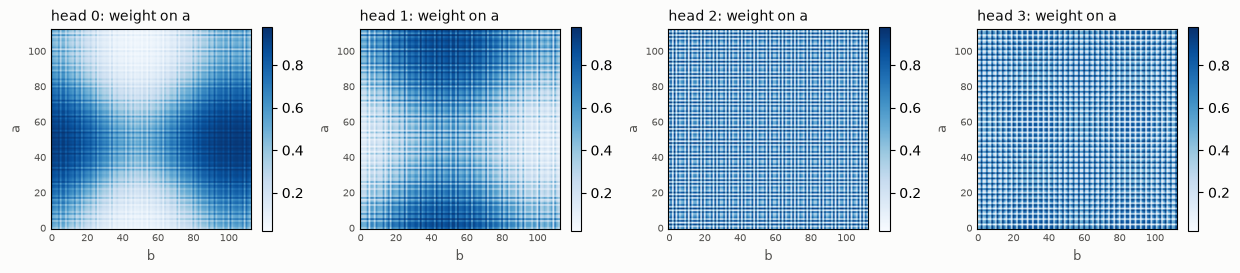

In [7]:
attn = cache[("core.0.0.attn.hook_attn", 0)][:, :, -1]  # (p*p, heads, 3 positions)
print("mean attention from '=' to [a, b, =] per head:")
for h in range(attn.shape[1]):
    print(f"  head {h}:", [round(v, 3) for v in attn[:, h].mean(0).tolist()])

on_a = attn[:, :, 0].reshape(p, p, -1)
coef = mech.fourier_2d(on_a - on_a.mean((0, 1)), basis)
best, frac = mech.neuron_frequencies(coef)
kept = mech.keep_frequencies_2d(on_a, basis, KEYS)
r2 = 1 - (on_a - kept).pow(2).sum((0, 1)) / (on_a - on_a.mean((0, 1))).pow(2).sum((0, 1))
for h in range(on_a.shape[-1]):
    print(f"  head {h}: weight on a, best single frequency {best[h].item()} (explains {frac[h]:.2f}); "
          f"all key frequencies explain {r2[h]:.2f}")

fig, axes = new_fig(1, on_a.shape[-1], height=3.2)
for h, ax in enumerate(axes):
    im = ax.imshow(on_a[:, :, h].cpu(), cmap="Blues", origin="lower")
    ax.set_title(f"head {h}: weight on a", loc="left", fontsize=10, color=pp.INK)
    ax.set_xlabel("b", fontsize=9, color=pp.INK_2); ax.set_ylabel("a", fontsize=9, color=pp.INK_2)
    ax.tick_params(labelsize=7, colors=pp.INK_2, length=0)
    fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.show()

## 4. Neurons cluster by frequency

The MLP activation of each neuron at `=`, over the (a, b) table, in the 2-D Fourier basis. For each neuron: the single frequency whose terms (constant, cos/sin(wa), cos/sin(wb) and their products) explain the most of its variance. Nanda et al. find almost every neuron is explained by one key frequency.

512 of 512 neurons ever fire
neurons with one frequency explaining > 0.85: 0.748
neurons with one frequency explaining > 0.95: 0.742
neurons per frequency (explained > 0.85): {1: 113, 49: 107, 33: 89, 37: 74}


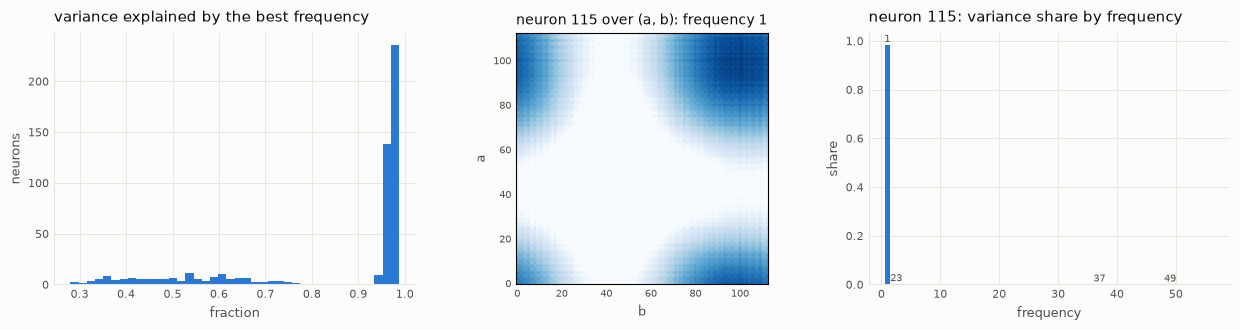

In [8]:
acts = cache[("core.0.0.mlp.hook_post", 0)][:, -1]  # (p*p, d_mlp)
grid = acts.reshape(p, p, -1)
live = grid.pow(2).sum((0, 1)) > 1e-8
best, frac = mech.neuron_frequencies(mech.fourier_2d(grid, basis))
best, frac = best[live], frac[live]
print(f"{int(live.sum())} of {grid.shape[-1]} neurons ever fire")
for thr in (0.85, 0.95):
    print(f"neurons with one frequency explaining > {thr}: {(frac > thr).float().mean():.3f}")
counts = {f: int(((best == f) & (frac > 0.85)).sum()) for f in sorted(set(best.tolist()))}
print("neurons per frequency (explained > 0.85):", {f: c for f, c in sorted(counts.items(), key=lambda kv: -kv[1]) if c})

fig, axes = new_fig(1, 3, height=3.4)
panel(axes[0], "variance explained by the best frequency", "fraction", "neurons")
axes[0].hist(frac.cpu(), bins=40, color=pp.SERIES[0])
# the clearest neuron of the lowest key frequency, which is easiest to see on the table
f = min(f for f in counts if counts[f])
n = int(t.where(best == f, frac, t.zeros_like(frac)).argmax())
idx = t.nonzero(live)[:, 0][n]
axes[1].imshow(grid[:, :, idx].cpu(), cmap="Blues", origin="lower")
axes[1].set_title(f"neuron {idx.item()} over (a, b): frequency {f}", loc="left", fontsize=10, color=pp.INK)
axes[1].set_xlabel("b", fontsize=9, color=pp.INK_2); axes[1].set_ylabel("a", fontsize=9, color=pp.INK_2)
axes[1].tick_params(labelsize=7, colors=pp.INK_2, length=0)
sq = mech.fourier_2d(grid[:, :, idx:idx + 1], basis)[..., 0].pow(2)
total = sq.sum() - sq[0, 0]
share = t.stack([(sq[r][:, r].sum() - sq[0, 0]) / total for r in ([0, 2 * g - 1, 2 * g] for g in range(1, p // 2 + 1))])
freq_bars(axes[2], t.cat([t.zeros(1), share]), KEYS, f"neuron {idx.item()}: variance share by frequency", "share")
plt.tight_layout(); plt.show()

## 5. The neuron-logit map reads each cluster out at its own frequency

W_L = W_out^T W_U maps each neuron to the logits. Its rows' Fourier norms over the output c should sit at the key frequencies, and each neuron's row at that neuron's own frequency.

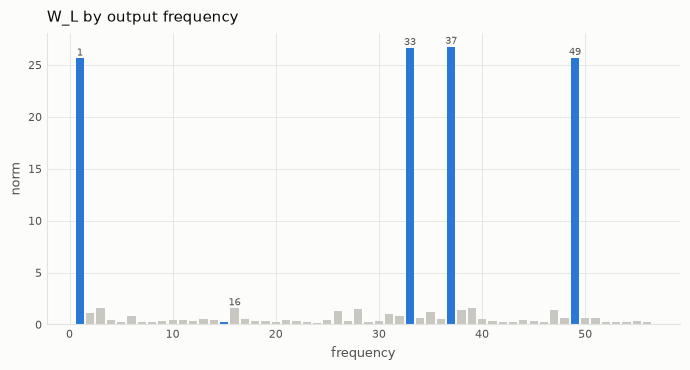

share of each clustered neuron's W_L row norm^2 at its own frequency: median 0.970
gini of W_L by frequency: 0.788


In [9]:
W_L = model.core[0][0].mlp.W_out.T @ model.unembed.W_U  # (d_mlp, p)
fig, axes = new_fig(1, 1, width=7)
freq_bars(axes[0], mech.freq_norms(W_L, basis), KEYS, "W_L by output frequency")
plt.tight_layout(); plt.show()
row_norms = (W_L[live] @ basis.T).pow(2)
own = t.stack([row_norms[i, [2 * f - 1, 2 * f]].sum() for i, f in enumerate(best.tolist())])
clean = frac > 0.85
print(f"share of each clustered neuron's W_L row norm^2 at its own frequency: "
      f"median {(own[clean] / row_norms[clean].sum(1)).median():.3f}")
print(f"gini of W_L by frequency: {progress.gini(mech.freq_norms(W_L, basis)[1:]):.3f}")

## 6. The logits form a clock

The **restricted loss** keeps only the cos/sin(w(a+b)) components of the logits at the key frequencies (plus their mean). The **excluded loss** removes those components on the train pairs. A least-squares fit of logit(c) by cos/sin(w(a + b − c)) shows how much of the logit variance the clock form explains.

In [10]:
fitted, r2 = mech.clock_fit(logits, labels, KEYS, p)
print(f"restricted loss {measures['restricted_loss']:.2e}   excluded loss {measures['excluded_loss']:.3f}   "
      f"full test loss {measures['grid_test_loss']:.2e}")
print("excluded loss per key frequency:", dict(zip(KEYS, [round(v, 3) for v in measures["excluded_loss_per_freq"]])))
print(f"clock fit with {len(KEYS)} key frequencies explains {r2:.4f} of the row-centred logit variance")
loss, acc = mech.loss_and_acc(fitted, labels)
print(f"clock-fit logits alone: loss {loss:.3e}, acc {acc:.4f}")

restricted loss 7.21e-08   excluded loss 7.532   full test loss 2.44e-07
excluded loss per key frequency: {37: 0.68, 1: 0.222, 49: 0.254, 33: 0.046, 15: 0.0}
clock fit with 5 key frequencies explains 0.9286 of the row-centred logit variance
clock-fit logits alone: loss 5.495e-08, acc 1.0000


## 7. Trig-identity replacement of the neurons

Each neuron's activation over (a, b) is replaced by its projection onto terms built only from the key frequencies, i.e. the trig identities the algorithm needs. The rest of the network is left as is. The opposite ablation removes exactly those terms. First check that recomputing the logits from the cached residual stream and neuron activations reproduces the model's output.

In [11]:
blk = model.core[0][0]
resid_mid = cache[("core.0.0.hook_resid_mid", 0)][:, -1]


def logits_from(neurons):
    """logits at '=' when the mlp neurons take the given values over the grid.

    args:
        neurons: tensor of shape (p*p, d_mlp).
    returns:
        logits of shape (p*p, p).
    """
    return model.unembed.unembed(resid_mid + neurons @ blk.mlp.W_out.T + blk.mlp.b_out)


assert t.allclose(logits_from(acts), logits, atol=1e-3)
kept = mech.keep_frequencies_2d(grid, basis, KEYS).reshape(p * p, -1)
const = grid.mean((0, 1), keepdim=True).reshape(1, -1)
removed = acts - (kept - const)
rows = [("original", acts), ("key-frequency terms only", kept), ("key-frequency terms removed", removed)]
print(f"{'neurons':<30} {'loss':>10} {'acc':>7}   share of neuron variance kept")
for name, n in rows:
    loss, acc = mech.loss_and_acc(logits_from(n), labels)
    var = ((n - n.mean(0)).pow(2).sum() / (acts - acts.mean(0)).pow(2).sum()).item()
    print(f"{name:<30} {loss:>10.3e} {acc:>7.4f}   {var:.3f}")

neurons                              loss     acc   share of neuron variance kept
original                        2.000e-07  1.0000   1.000
key-frequency terms only        1.134e-07  1.0000   0.976
key-frequency terms removed     6.106e+00  0.0398   0.024


## 8. Progress measures over training

Recomputed from each saved checkpoint (log-spaced), using the same functions as during training, with the phase boundaries from section 1.

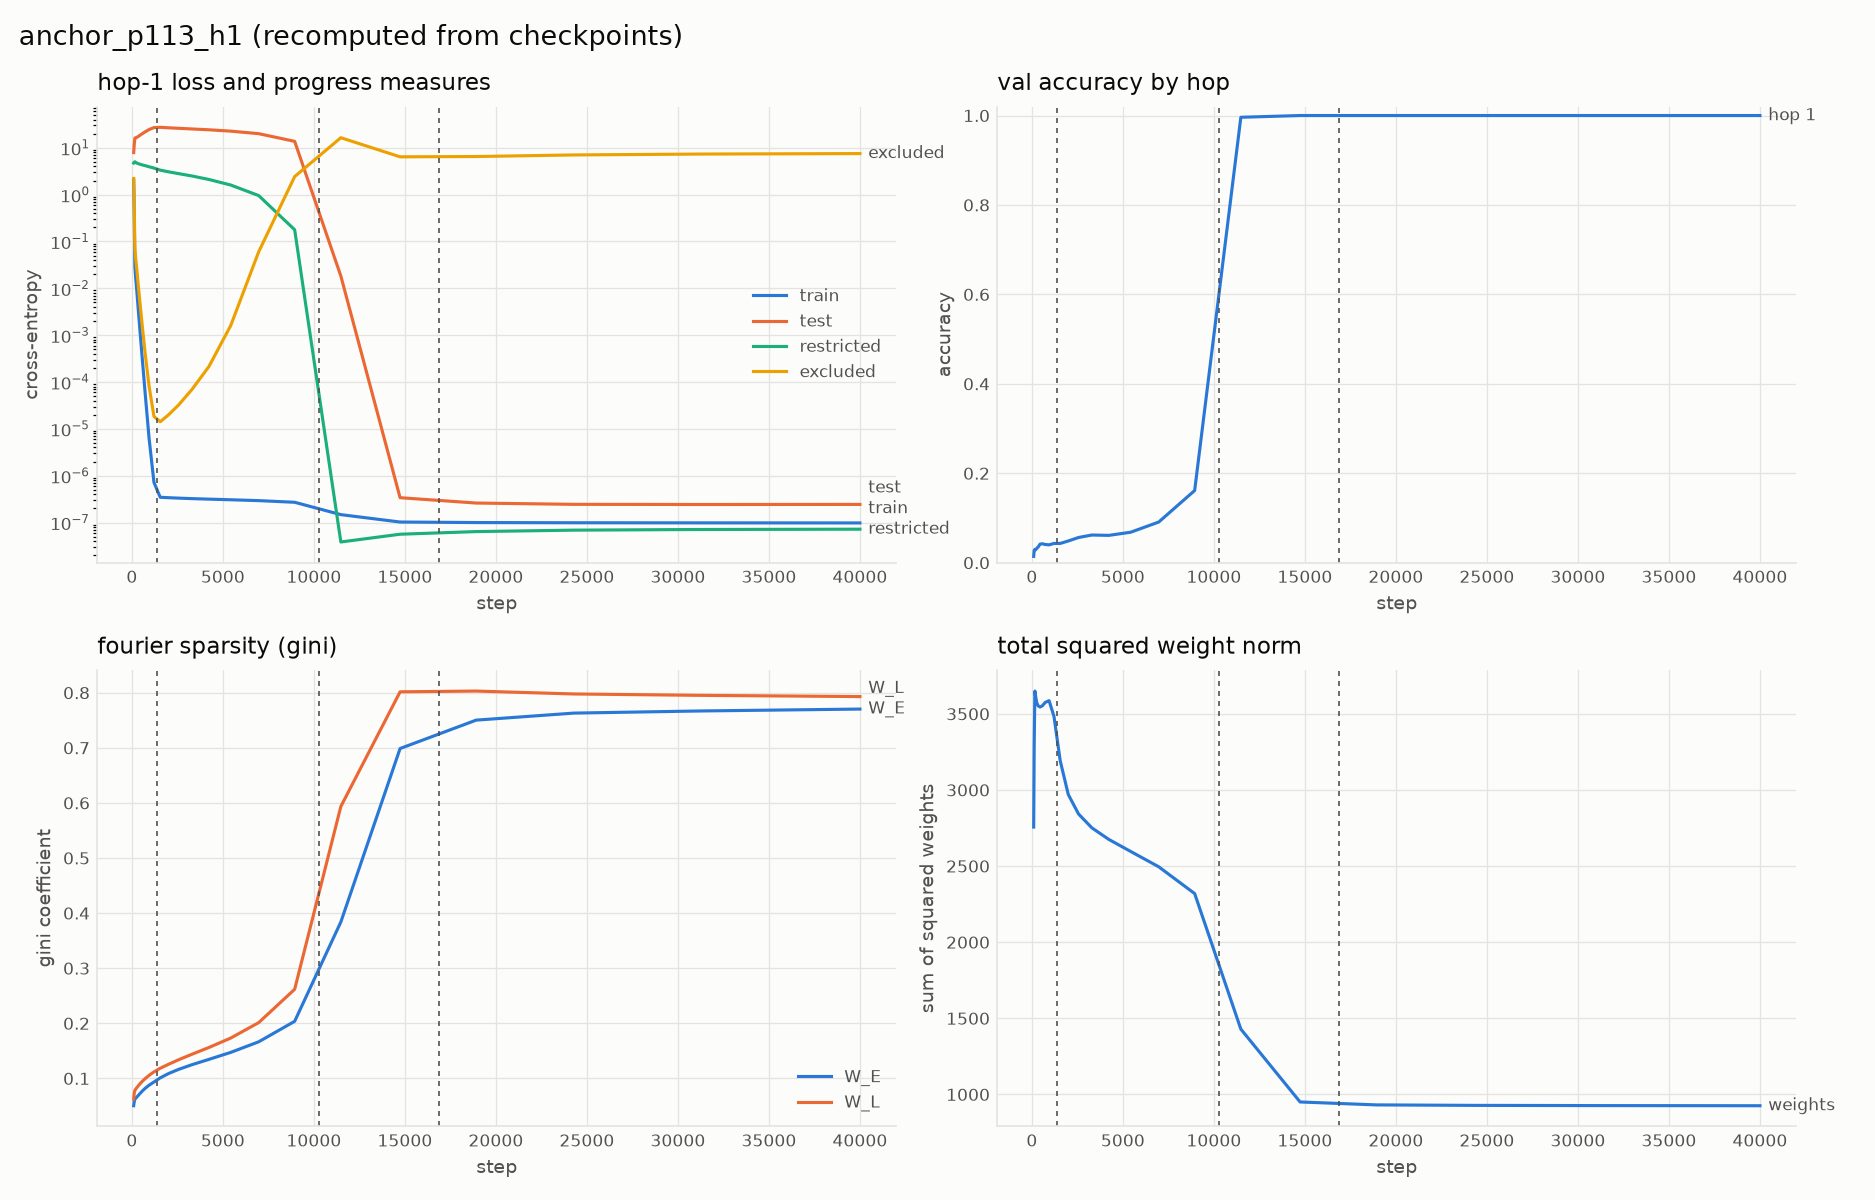

In [12]:
rows = analysis.recompute(run, DEVICE)
out = pp.plot_rows(rows, f"{run['name']} (recomputed from checkpoints)",
                   run["run_dir"] / "analysis" / "nanda_progress_recomputed.png", PHASES)
display(Image(filename=str(out)))

## Reading

Numbers are for `final.pt`; everything above is deterministic on CPU.

**The run reproduces the paper.**

- **Phases.** Memorization ends at the test-loss peak at step 1.4k, matching the paper's ~1.4k. Grokking (test accuracy > 0.5) comes at 10.3k, against the paper's 9.4k for the start of cleanup. Cleanup ends at 16.9k by our criterion (Σw² within 1% of its final value), which is stricter than the paper's ~13k.
- **Sparse embedding.** The share of W_E's norm² in the top 5 frequencies rises from 0.11 at step 100 to 0.99, and its gini from 0.04 to 0.77. The logits use **4 real key frequencies (37, 1, 49, 33)**. The fifth (15) has a small logit norm and an excluded loss of 0.00, so the model doesn't need it. W_E also carries frequency 47, which the logits barely use.
- **Attention.** Every head splits its attention evenly between `a` and `b`, with almost nothing on `=`. Key-frequency terms explain 0.97–1.00 of how the weight on `a` varies over the table.
- **Neurons.** 75% of neurons are explained > 0.85 by one frequency, in four clusters (1: 113, 49: 107, 33: 89, 37: 74). The remaining quarter forms the left tail of the histogram.
- **Neuron-logit map.** A clustered neuron's W_L row puts a median 0.97 of its norm² on its own frequency. W_L's gini is 0.79.
- **Clock.** Restricted loss (7e-8) is as low as the full loss, while excluded loss is 7.5. A 5-frequency clock fit explains 0.93 of the logit variance. Frequency 37 matters most (excluded loss 0.68 when removed alone).
- **Trig-identity replacement.** Keeping only the key-frequency terms of every neuron (97.6% of neuron variance) leaves the model perfect: loss 1e-7, accuracy 1.000. Removing them leaves 2.4% of the variance and accuracy 0.04, near chance.

This is the reference model for checking that our tools work.